# 01 - Exponential growth: the Malthus model

**MATH 331 - Differential Equations.** Syllabus units U1 (definitions, verifying solutions, IVPs),
U2 (separable equations, existence and uniqueness), U4 (growth and decay).
Lecture plan: Sessions 3, 4 and 7.

**Reference text** (free for students): J. Lebl, *Notes on Diffy Qs: Differential Equations for
Engineers*, file `ode/FullText_Diff_Eq_For_Engineers.pdf`:
Section 0.2 (Example 0.2.1, bacteria), 0.3 (classification), 1.1 (integrals as solutions),
1.2 (slope fields, Picard's theorem 1.2.1), 1.3 (separable equations).
Cross-checked with W.A. Adkins and M.G. Davidson, *Ordinary Differential Equations*
(Springer, 2012), Section 1.3, and J.D. Logan, *An Introduction to Nonlinear Differential
Equations* (Wiley, 2007), Chapter 1.

**What you will learn**
1. How a modelling assumption ("the rate of growth is proportional to the population")
   becomes an initial value problem.
2. Why that problem has exactly one solution, and on which interval (Picard's theorem).
3. How to solve it by separation of variables, carefully, and how to verify the result.
4. How to read a slope field, and how a numerical solution compares with the exact one.
5. What the model does and does not say about the real world.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (analytic solutions, Euler/Heun/RK4, slope fields, phase lines).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import Math, display                 # noqa: F401  (not used in every notebook)
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 1. The model

Let $P(t)$ be the number of bacteria on a Petri dish at time $t$. If food and space are
abundant, a population twice as large produces twice as many new bacteria per unit time.
In other words, the **rate of growth is proportional to the population** (Lebl, Section 0.2;
the *Malthusian growth law* in Adkins and Davidson, Section 1.1):

$$
\boxed{\;\frac{dP}{dt} = k\,P, \qquad P(t_0) = P_0\;}
\qquad\qquad k > 0 \ \text{(growth rate, units of } 1/\text{time}).
$$

* $k$ is the **relative (per-capita) growth rate**: $\dfrac{1}{P}\dfrac{dP}{dt} = k$.
  For example, $k = 0.069\ \text{s}^{-1}$ means about 6.9 % more bacteria per second (for small
  time steps).
* The equation together with the condition $P(t_0) = P_0$ is an **initial value problem (IVP)**.
* Modelling assumptions: unlimited resources, no deaths or births depending on crowding,
  a population large enough to be treated as a real-valued, differentiable function.
  The last point is an idealisation, because a population is an integer (Lebl, Section 0.2).

### Classification (Lebl, Section 0.3)

| Property | $P' = kP$ | Why |
|---|---|---|
| order | first | the highest derivative is $P'$ |
| ordinary | yes | one independent variable, $t$ |
| linear | yes | $P$ and $P'$ appear to the first power, not multiplied together |
| homogeneous | yes | no term free of $P$ |
| constant coefficient | yes | $k$ does not depend on $t$ |
| autonomous | yes | the right-hand side does not depend on $t$ explicitly |

## 2. Existence and uniqueness

Write the equation as $P' = f(t, P)$ with $f(t,P) = kP$. **Picard's theorem** (Lebl, Theorem
1.2.1) states:

> If $f(x,y)$ is continuous and $\partial f/\partial y$ exists and is continuous near
> $(x_0, y_0)$, then a solution to $y' = f(x,y)$, $y(x_0) = y_0$ exists (at least for $x$ in some
> small interval) and is unique.

Here $f(t,P) = kP$ and $\partial f/\partial P = k$ are continuous on the whole plane, so for
**every** initial condition $(t_0, P_0)$ there is exactly one solution near $t_0$.

Picard's theorem is *local*. For this linear equation the solution actually exists for all
$t\in\mathbb{R}$: we will find it explicitly, and it is defined everywhere. Compare with
$y' = y^2$ (Lebl, Example 1.2.3), whose solutions blow up in finite time although the
right-hand side is just as smooth.

**A consequence we will use.** $P \equiv 0$ is a solution (the *equilibrium* solution).
By uniqueness, no other solution can ever take the value $0$, since two different solutions
would then pass through the same point. Hence a solution with $P_0 > 0$ stays positive
for all $t$, and **dividing by $P$ is legitimate**.

## 3. Analytical solution by separation of variables (Lebl, Section 1.3)

For $P_0 \neq 0$, $P(t)$ never vanishes, so we may divide by $P$:

$$
\frac{1}{P}\frac{dP}{dt} = k
\;\;\Longrightarrow\;\;
\int_{t_0}^{t} \frac{P'(s)}{P(s)}\,ds = \int_{t_0}^{t} k\,ds
\;\;\Longrightarrow\;\;
\ln\left|\frac{P(t)}{P_0}\right| = k\,(t - t_0).
$$

Because $P(t)$ and $P_0$ have the same sign, $|P(t)/P_0| = P(t)/P_0$, and

$$
\boxed{\;P(t) = P_0\,e^{k (t - t_0)}\;}
$$

This formula also covers $P_0 = 0$. Using **definite** integrals from $t_0$ to $t$
avoids the arbitrary constant and the $\pm$ sign discussion of the indefinite version
(Lebl, Example 1.1.3; Adkins and Davidson, Section 1.3).

**Verification** (always check a candidate solution: Lebl, Section 0.2):
$\;P'(t) = k P_0 e^{k(t-t_0)} = k P(t)$ and $P(t_0) = P_0$. ✓

**Doubling time.** $P(t + T_2) = 2P(t)$ gives $e^{kT_2} = 2$, that is
$T_2 = \dfrac{\ln 2}{k}$. It does not depend on $t$ or on $P_0$: the population doubles every
$T_2$, whatever its size.

SymPy confirms the derivation symbolically:

In [2]:
t, t0 = sp.symbols("t t_0", real=True)
k = sp.symbols("k", positive=True)
P0 = sp.symbols("P_0", real=True)
P = sp.Function("P")

ivp = sp.Eq(P(t).diff(t), k * P(t))
solution = sp.dsolve(ivp, P(t), ics={P(t0): P0})
display(Math(r"\text{dsolve: } " + sp.latex(solution)))

# checkodesol substitutes the solution into the ODE: (True, 0) means it satisfies it
print("checkodesol:", sp.checkodesol(ivp, solution))
T2 = sp.solve(sp.Eq(sp.exp(k * sp.Symbol("T_2")), 2), sp.Symbol("T_2"))
display(Math(r"T_2 = " + sp.latex(T2[0])))

<IPython.core.display.Math object>

checkodesol: (True, 0)


<IPython.core.display.Math object>

## 4. A worked example: Lebl, Example 0.2.1

> *There are 100 bacteria at time 0 and 200 bacteria 10 seconds later. How many bacteria will
> there be 1 minute from time 0?*

Two data points fix the two unknowns $P_0$ and $k$:
$P(0) = 100 \Rightarrow P_0 = 100$, and $P(10) = 100\,e^{10k} = 200 \Rightarrow
k = \dfrac{\ln 2}{10} \approx 0.0693\ \text{s}^{-1}$ (so the doubling time is 10 s). Then

$$P(60) = 100\,e^{6\ln 2} = 100\cdot 2^6 = 6400 .$$

Lebl also notes $P(61) \approx 6859.35$: the model happily returns non-integer populations.
The code below reproduces both numbers, and the `assert` statements stop the notebook if they
were wrong.

In [3]:
k_bact = ol.growth_rate_from_two_values(0, 100, 10, 200)
P60 = ol.exponential_solution(60, 100, k_bact)
P61 = ol.exponential_solution(61, 100, k_bact)
print(f"k = ln 2 / 10 = {k_bact:.5f} 1/s,  doubling time = {np.log(2) / k_bact:.2f} s")
print(f"P(60) = {P60:.2f},  P(61) = {P61:.2f}")
assert np.isclose(P60, 6400) and np.isclose(P61, 6859.35, atol=0.01)   # Lebl, Example 0.2.1

k = ln 2 / 10 = 0.06931 1/s,  doubling time = 10.00 s
P(60) = 6400.00,  P(61) = 6859.35


## 5. The slope field (Lebl, Section 1.2)

At every point $(t, P)$ the equation prescribes the slope $kP$ of the solution through that
point. Drawing short segments of that slope gives the **slope field**. Solutions are the curves
tangent to it everywhere. Note that:

* the slopes depend on $P$ only (the equation is autonomous), so the field is the same along
  every horizontal line;
* $P = 0$ is an equilibrium, and by uniqueness the other solutions never cross it;
* solutions above it grow faster and faster, and those below it (negative $P$, mathematically
  allowed) decrease without bound.

**Static figure** (default values; the sliders in the next cell need a running kernel):

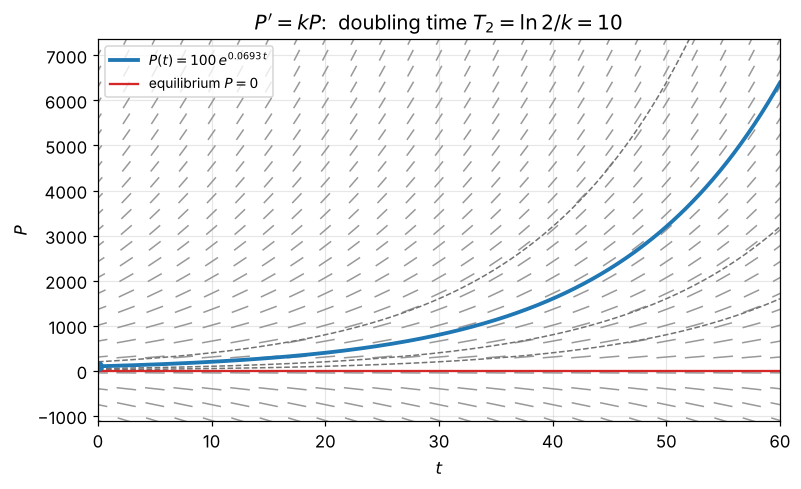

In [4]:
def plot_growth(k=0.0693, P0=100.0, t_end=60.0):
    """Slope field of P' = kP with the solution through (0, P0) and a few neighbours."""
    t = np.linspace(0, t_end, 400)
    P_top = 1.15 * max(ol.exponential_solution(t_end, P0, k), P0)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ol.slope_field(ax, lambda tt, pp: k * pp, (0, t_end), (-0.15 * P_top, P_top), n=25)
    for factor in (0.25, 0.5, 2.0):                         # neighbouring solutions
        ax.plot(t, ol.exponential_solution(t, factor * P0, k), color="0.45", lw=1, ls="--")
    ax.plot(t, ol.exponential_solution(t, P0, k), color="C0", lw=2.5,
            label=rf"$P(t) = {P0:g}\,e^{{{k:.4g}\,t}}$")
    ax.axhline(0, color="C3", lw=1.5, label="equilibrium $P = 0$")
    ax.plot([0], [P0], "o", color="C0")
    ax.set_xlabel("$t$")
    ax.set_ylabel("$P$")
    ax.set_title(rf"$P' = kP$:  doubling time $T_2 = \ln 2 / k = {np.log(2) / k:.3g}$")
    ax.legend(loc="upper left")
    plt.show()


plot_growth()

**Explore** (requires a running kernel): change the growth rate $k$ (negative values give
decay), the initial population $P_0$ and the length of the time interval.

In [5]:
interact(plot_growth,
         k=FloatSlider(value=0.0693, min=-0.1, max=0.15, step=0.0005, readout_format=".4f",
                       description="k", continuous_update=False),
         P0=FloatSlider(value=100, min=-100, max=500, step=10, description="P0",
                        continuous_update=False),
         t_end=FloatSlider(value=60, min=5, max=120, step=5, description="t max",
                           continuous_update=False));

interactive(children=(FloatSlider(value=0.0693, continuous_update=False, description='k', max=0.15, min=-0.1, …

## 6. Numerical solution and comparison

Most ODEs cannot be solved in closed form. Here we can, so the exact solution lets us
**measure** the error of numerical methods (the topic of notebook 04):

* **Euler's method** (Lebl, Section 1.7): $P_{i+1} = P_i + h\,kP_i = (1 + hk)P_i$, so
  $P_n = (1+hk)^n P_0$. As $h \to 0$ with $nh = t$ fixed, $(1+hk)^{t/h} \to e^{kt}$: Euler's
  method converges to the exact solution. This limit is the classical definition of $e$.
* **`scipy.integrate.solve_ivp`**: an adaptive Runge-Kutta method (RK45) with error control.

For growth ($k > 0$), $1 + hk < e^{hk}$, so Euler **always underestimates** the population.

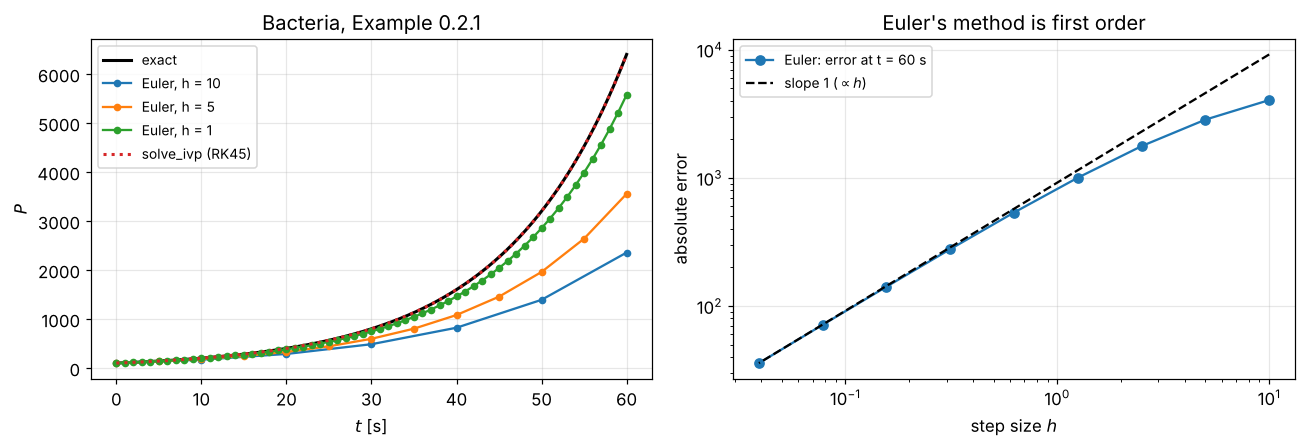

solve_ivp: P(60) = 6400.000001  (exact 6400)
observed orders of Euler: [0.507 0.686 0.819 0.902 0.949 0.974 0.987 0.993]


In [6]:
k_num, P0_num, t_end = k_bact, 100.0, 60.0
exact = lambda tt: ol.exponential_solution(tt, P0_num, k_num)          # noqa: E731

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
t_fine = np.linspace(0, t_end, 400)
ax1.plot(t_fine, exact(t_fine), "k", lw=2, label="exact")
for h in (10.0, 5.0, 1.0):
    t_e, P_e = ol.euler(lambda tt, pp: k_num * pp, (0, t_end), P0_num, h)
    ax1.plot(t_e, P_e, "o-", ms=4, label=f"Euler, h = {h:g}")
sol = solve_ivp(lambda tt, pp: k_num * pp, (0, t_end), [P0_num], rtol=1e-10, atol=1e-8,
                dense_output=True)
ax1.plot(t_fine, sol.sol(t_fine)[0], "C3:", lw=2, label="solve_ivp (RK45)")
ax1.set_xlabel("$t$ [s]")
ax1.set_ylabel("$P$")
ax1.legend()
ax1.set_title("Bacteria, Example 0.2.1")

steps = 10.0 / 2 ** np.arange(0, 9)
errors = [abs(ol.euler(lambda tt, pp: k_num * pp, (0, t_end), P0_num, h)[1][-1] - exact(t_end))
          for h in steps]
ax2.loglog(steps, errors, "o-", label="Euler: error at t = 60 s")
ax2.loglog(steps, errors[-1] * steps / steps[-1], "k--", label=r"slope 1 ($\propto h$)")
ax2.set_xlabel("step size $h$")
ax2.set_ylabel("absolute error")
ax2.legend()
ax2.set_title("Euler's method is first order")
plt.tight_layout()
plt.show()

print(f"solve_ivp: P(60) = {sol.y[0, -1]:.6f}  (exact 6400)")
print("observed orders of Euler:", np.round(ol.observed_order(errors), 3))

## 7. Interpretation and limits of the model

* **Prediction, not certainty.** $P(60) = 6400$ means *approximately* 6400 bacteria, provided
  the assumptions hold (Lebl, Section 0.2).
* **Unbounded growth is unrealistic.** $P(t) \to \infty$ as $t\to\infty$. Resources are finite, so
  the growth rate must eventually decrease. That is the **logistic model** of notebook 03.
* **Sensitivity to $k$.** An error $\delta k$ in the growth rate changes the prediction by a
  relative amount $\delta P/P = t\,\delta k$, which grows linearly in time: long-term
  predictions of exponential models are fragile.
* **Same equation, different physics.** $y' = ky$ also describes compound interest (continuous
  compounding), the decay of radioactive isotopes ($k<0$, notebook 02) and the discharge of a
  capacitor through a resistor ($k = -1/RC$).

## 8. Exercises

1. *(Lebl, Exercise 0.E.0.2.10)* The population of city X was 100 thousand 20 years ago, and
   120 thousand 10 years ago. Assuming exponential growth, estimate the population now.
   *Check:* $100\cdot(1.2)^2 = 144$ thousand.
2. *(Lebl, exercises of Section 1.3)* Bacteria grow while a toxic substance is slowly added, so that
   $\frac{dP}{dt} = (2 - 0.1\,t)P$, $P(0) = 1000$. The equation is separable but **not**
   autonomous. Find $P(5)$, and the time at which the population is largest.
3. Prove that $(1 + hk)^{t/h} \to e^{kt}$ as $h \to 0^+$ (take logarithms and use
   $\ln(1+x) = x - x^2/2 + O(x^3)$). Conclude that Euler's method converges for $P' = kP$.
4. Use Picard's theorem to explain why two solutions of $P' = kP$ cannot cross. Why does the
   argument fail for $y' = 2\sqrt{|y|}$ (Lebl, Example 1.2.2)?
5. A quantity grows by 3 % per year. Compare the doubling time $\ln 2/k$ with the "rule of 70"
   ($70/3$ years). Explain where the 70 comes from.